<a href="https://colab.research.google.com/github/fahimshahariar1/transaction-fraud-detector/blob/main/Transaction_Fraud_Detector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transaction Fraud Detector
In today's digital world transation fraud is a regular thing. In this notebook we will try to use AI ML to detect the fraud and also would try to prevent it

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold


In [35]:
creditCardUrl = "/content/drive/MyDrive/AI ML/creditcard.csv"
creditCard_df = pd.read_csv(creditCardUrl)
creditCard_df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [36]:
creditCard_df.shape

(284807, 31)

In [37]:
creditCard_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

## 1. Explaratory Data Analysis

Before training a fraud detection model, we investigate data quality,
class imbalance, transaction characteristics, and potential preprocessing
requirements.

In [38]:
creditCard_df.isnull().sum().sum()

np.int64(0)

In [39]:
creditCard_df["Class"].value_counts()

,count
Class,
0,284315
1,492


In [40]:
print("Duplicate Rows: ",creditCard_df.duplicated().sum())

Duplicate Rows:  1081


In [41]:
creditCard_df[creditCard_df.duplicated(keep=False)].head(10)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
220,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0
221,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0


In [42]:
creditCard_df["Class"].value_counts(normalize=True) * 100

,proportion
Class,
0,99.827251
1,0.172749


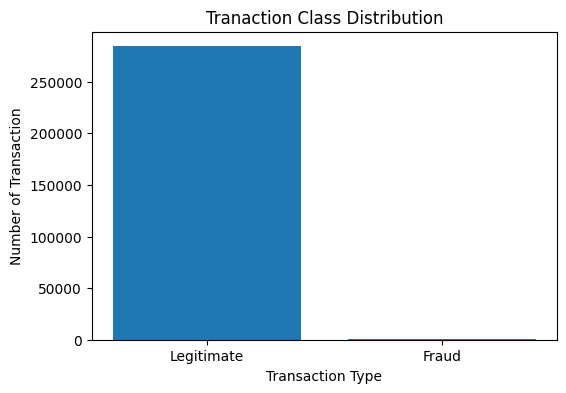

In [43]:
class_counts = creditCard_df["Class"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(["Legitimate", "Fraud"], class_counts.values)

plt.title("Tranaction Class Distribution")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transaction")

plt.show()

In [44]:
fraud_count = creditCard_df["Class"].sum()
total_transaction = len(creditCard_df)

fraud_percentage = fraud_count / total_transaction * 100

print(f"Total number of transaction: {total_transaction}")
print(f"Number of fraud transaction: {fraud_count}")
print(f"Percentage of fraud transaction: {fraud_percentage:.2f}%")

Total number of transaction: 284807
Number of fraud transaction: 492
Percentage of fraud transaction: 0.17%


In [45]:
creditCard_df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


In [46]:
legitimate = creditCard_df[creditCard_df["Class"] == 0]
fraud = creditCard_df[creditCard_df["Class"] == 1]

print("Legitimate Transaction Amount:")
print(legitimate["Amount"].describe())

print("\nFraud Transaction Amount:")
print(fraud["Amount"].describe())

Legitimate Transaction Amount:
count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64

Fraud Transaction Amount:
count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64


In [47]:
creditCard_df["TimeHours"] = creditCard_df["Time"] / 3600
creditCard_df.groupby("Class")["TimeHours"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,26.343945,13.190004,0.000000,15.063889,23.530833,38.703611,47.997778
1,492.0,22.429669,13.287601,0.112778,11.455972,20.991250,35.689722,47.318889


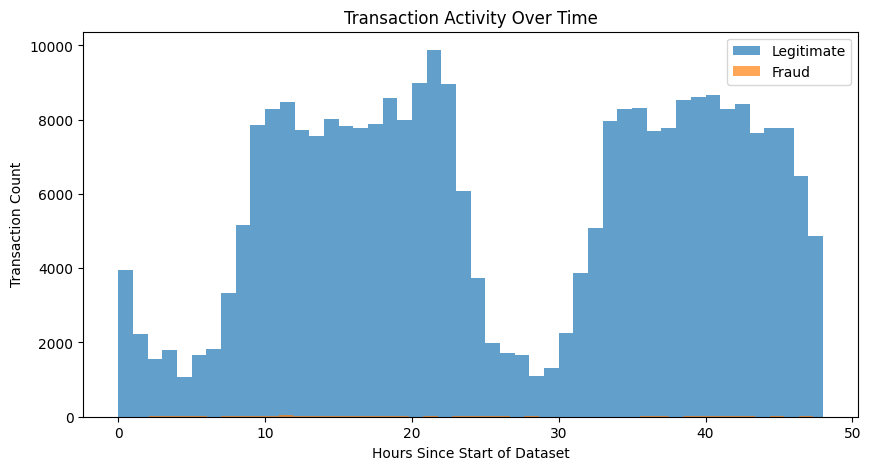

In [48]:
plt.figure(figsize=(10, 5))

plt.hist(
    legitimate["Time"] / 3600,
    bins=48,
    alpha=0.7,
    label="Legitimate"
)

plt.hist(
    fraud["Time"] / 3600,
    bins=48,
    alpha=0.7,
    label="Fraud"
)

plt.xlabel("Hours Since Start of Dataset")
plt.ylabel("Transaction Count")
plt.title("Transaction Activity Over Time")
plt.legend()

plt.show()

## Initial Observations


• The dataset contains 284,807 transactions and 31 original features.

• Only 492 transactions are fraudulent, representing approximately
  0.173% of the dataset, indicating severe class imbalance.

• There are no missing values, therefore missing-value imputation is
  currently unnecessary.

• 1,081 rows are detected as duplicates. These should be investigated
  before deciding whether they represent redundant records or valid
  repeated transactions.

• Fraudulent transactions have a higher mean amount but lower median
  amount than legitimate transactions, indicating that transaction
  amount is highly skewed and large transaction size alone cannot
  reliably identify fraud.

• Because the target class is highly imbalanced, accuracy will not be
  sufficient for evaluating model performance. Precision, recall,
  F1-score and precision-recall AUC will be more informative.


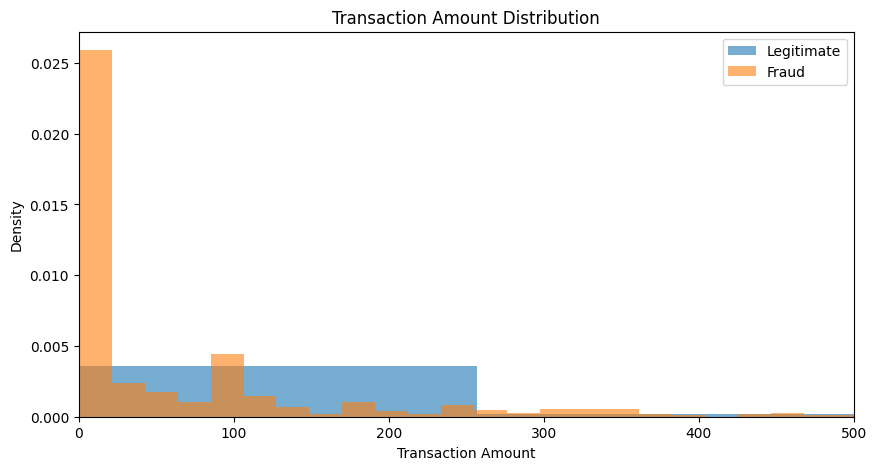

In [49]:
plt.figure(figsize=(10, 5))

plt.hist(
    legitimate["Amount"],
    bins=100,
    alpha=0.6,
    label="Legitimate",
    density=True
)

plt.hist(
    fraud["Amount"],
    bins=100,
    alpha=0.6,
    label="Fraud",
    density=True
)

plt.xlim(0, 500)

plt.xlabel("Transaction Amount")
plt.ylabel("Density")
plt.title("Transaction Amount Distribution")
plt.legend()

plt.show()

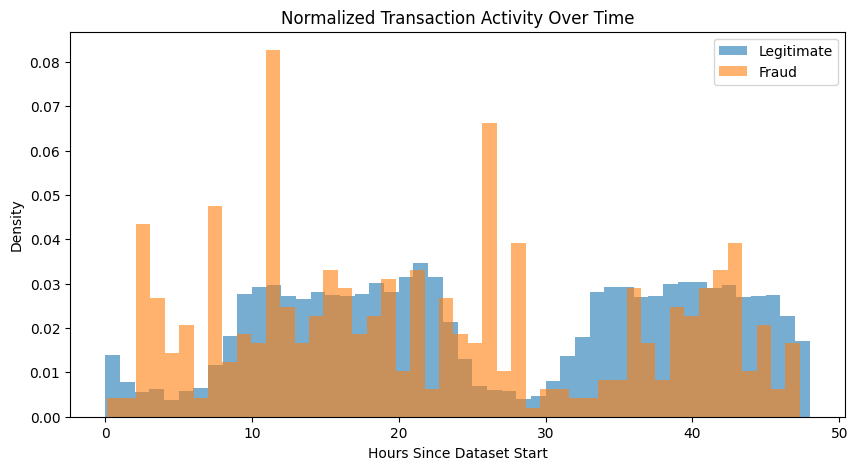

In [50]:
plt.figure(figsize=(10, 5))

plt.hist(
    legitimate["Time"] / 3600,
    bins=48,
    density=True,
    alpha=0.6,
    label="Legitimate"
)

plt.hist(
    fraud["Time"] / 3600,
    bins=48,
    density=True,
    alpha=0.6,
    label="Fraud"
)

plt.xlabel("Hours Since Dataset Start")
plt.ylabel("Density")
plt.title("Normalized Transaction Activity Over Time")
plt.legend()

plt.show()

In [51]:
creditCard_df.groupby("Class").mean().T

Class,0,1
Time,94838.202258,80746.806911
V1,0.008258,-4.771948
V2,-0.006271,3.623778
V3,0.012171,-7.033281
V4,-0.007860,4.542029
V5,0.005453,-3.151225
V6,0.002419,-1.397737
V7,0.009637,-5.568731
V8,-0.000987,0.570636
V9,0.004467,-2.581123


In [52]:
feature_means = creditCard_df.groupby("Class").mean().T

feature_means["Difference"] = (
    feature_means[1] - feature_means[0]
)

feature_means.sort_values(
    "Difference",
    key=abs,
    ascending=False
).head(10)

Class,0,1,Difference
Time,94838.202258,80746.806911,-14091.395347
Amount,88.291022,122.211321,33.920299
V3,0.012171,-7.033281,-7.045452
V14,0.012064,-6.971723,-6.983787
V17,0.011535,-6.665836,-6.677371
V12,0.010832,-6.259393,-6.270225
V10,0.009824,-5.676883,-5.686707
V7,0.009637,-5.568731,-5.578368
V1,0.008258,-4.771948,-4.780206
V4,-0.007860,4.542029,4.549889


In [53]:
correlation_with_class = (
    creditCard_df.corr()["Class"]
    .drop("Class")
    .sort_values()
)

correlation_with_class

,Class
V17,-0.326481
V14,-0.302544
V12,-0.260593
V10,-0.216883
V16,-0.196539
V3,-0.192961
V7,-0.187257
V18,-0.111485
V1,-0.101347
V9,-0.097733


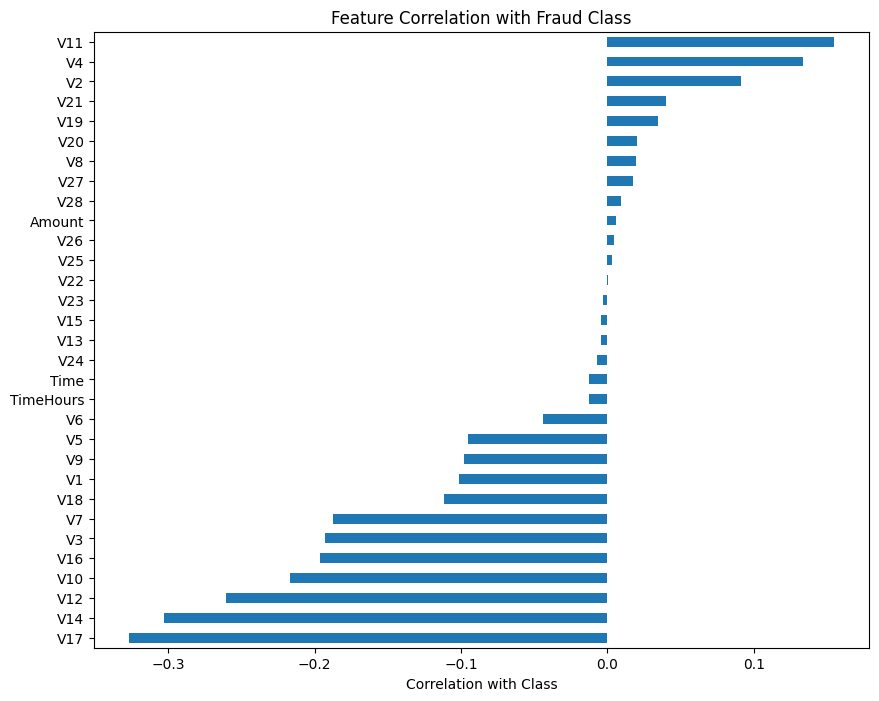

In [54]:
plt.figure(figsize=(10, 8))

correlation_with_class.plot(kind="barh")

plt.title("Feature Correlation with Fraud Class")
plt.xlabel("Correlation with Class")

plt.show()

In [55]:
duplicate_rows = creditCard_df[
    creditCard_df.duplicated(keep=False)
]

duplicate_rows["Class"].value_counts()

,count
Class,
0,1822
1,32


In [56]:
duplicate_summary = pd.crosstab(
    duplicate_rows["Class"],
    columns="count"
)

duplicate_summary

col_0,count
Class,
0,1822
1,32


In [57]:
print("Duplicated rows:", len(duplicate_rows))
print(
    "Fraud among duplicated rows:",
    (duplicate_rows["Class"] == 1).sum()
)
print(
    "Legitimate among duplicated rows:",
    (duplicate_rows["Class"] == 0).sum()
)

Duplicated rows: 1854
Fraud among duplicated rows: 32
Legitimate among duplicated rows: 1822


In [58]:
duplicate_rows.sort_values(
    by=list(creditCard_df.columns)
).head(20)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,TimeHours
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0,0.007222
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0,0.007222
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0,0.007222
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0,0.007222
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0,0.020556
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0,0.020556
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0,0.020556
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0,0.020556
220,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0,0.040278
221,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0,0.040278


In [59]:
top_features = [
    "V17",
    "V14",
    "V12",
    "V10",
    "V16",
    "V3"
]

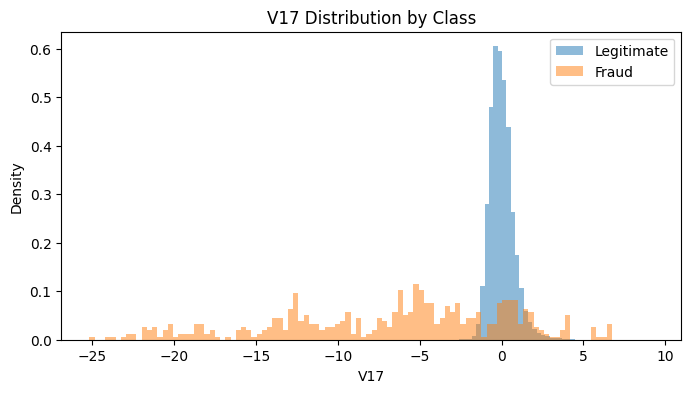

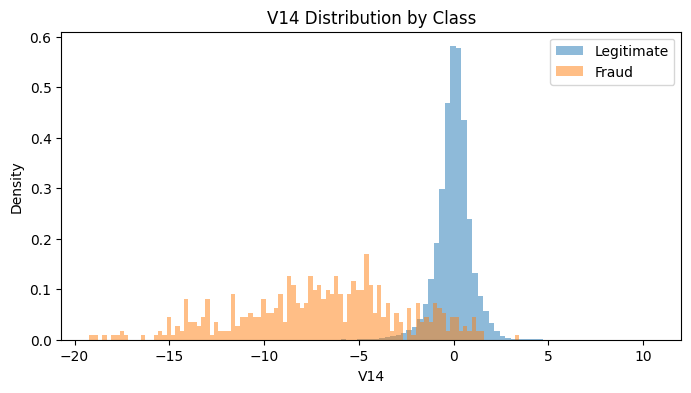

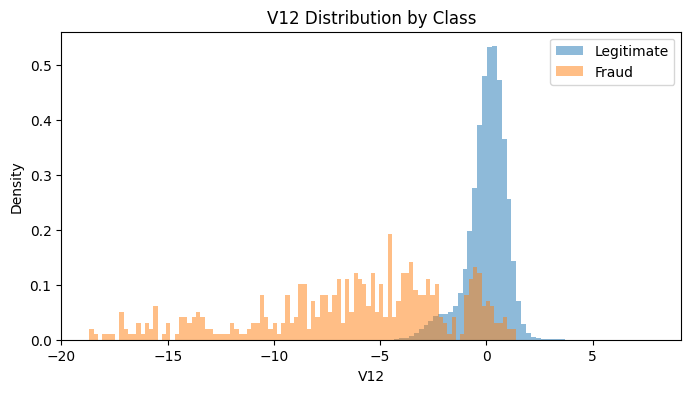

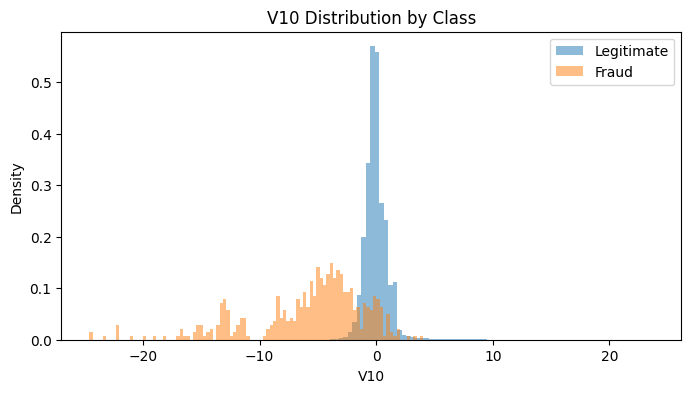

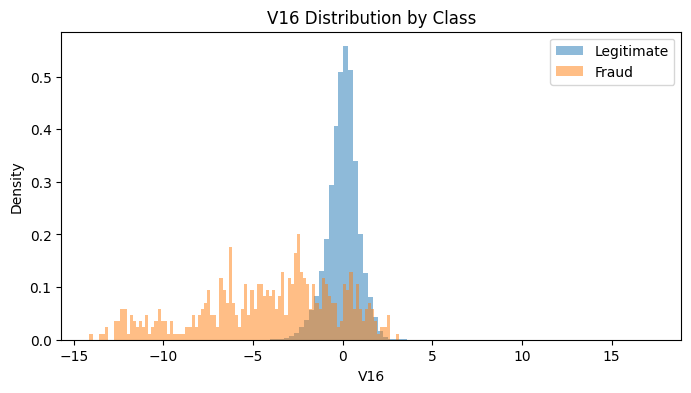

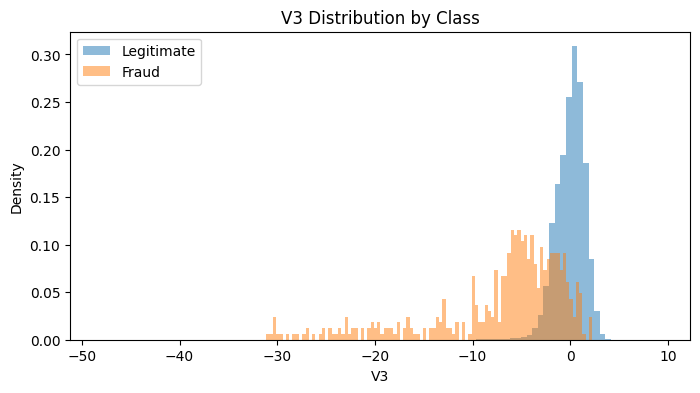

In [60]:
for feature in top_features:
    plt.figure(figsize=(8, 4))

    plt.hist(
        legitimate[feature],
        bins=100,
        density=True,
        alpha=0.5,
        label="Legitimate"
    )

    plt.hist(
        fraud[feature],
        bins=100,
        density=True,
        alpha=0.5,
        label="Fraud"
    )

    plt.title(f"{feature} Distribution by Class")
    plt.xlabel(feature)
    plt.ylabel("Density")
    plt.legend()

    plt.show()

In [61]:

base_df = creditCard_df.drop(
    columns=["TimeHours"],
    errors="ignore"
).copy()

repeated_rows = base_df.duplicated(keep=False)


extra_duplicates = base_df.duplicated(keep="first")

duplicate_audit = (
    base_df.assign(
        InRepeatedGroup=repeated_rows,
        ExtraDuplicate=extra_duplicates
    )
    .groupby("Class")[
        ["InRepeatedGroup", "ExtraDuplicate"]
    ]
    .sum()
)

print(duplicate_audit)

       InRepeatedGroup  ExtraDuplicate
Class                                 
0                 1822            1062
1                   32              19


1. What could happen if identical observations appear in both the training and test sets?
>If Identical observation appears in both the training and test sets then there is a possibility that our model would catagorize both as fraud or true transaction

2. Would you remove exact duplicates in this dataset, or preserve them and prevent duplicate groups from crossing the split? Explain your reasoning.
> I would keep them, cause duplicates doesn't really mean that they are fraudulent transactions or anything like that

# Phase 2: Model Development

In [62]:
X = base_df.drop(columns=["Class"])
y = base_df["Class"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (284807, 30)
Target: (284807,)


In [63]:
group_ids = pd.util.hash_pandas_object(
    X, index=False
).to_numpy()

print("Total Rows:", len(X))
print("Unique feature gropus:", len(np.unique(group_ids)))

Total Rows: 284807
Unique feature gropus: 283726


In [64]:
from IPython.testing import test
outer_split = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_val_idx, test_idx = next(
    outer_split.split(X, y, groups=group_ids)
)

inner_split = StratifiedGroupKFold(
    n_splits = 4,
    shuffle = True,
    random_state = 42
)

train_local, val_local = next(
    inner_split.split(
        X.iloc[train_val_idx],
        y.iloc[train_val_idx],
        groups=group_ids[train_val_idx]
    )
)

train_idx = train_val_idx[train_local]
val_idx = train_val_idx[val_local]

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]
y_test = y.iloc[test_idx]

In [64]:
train_groups = set(group_ids[train_idx])
val_groups = set(group_ids[val_idx])
test_groups = set(group_ids[test_idx])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

print("No identical feature groups cross splits!")

In [66]:
for name, target in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(
        f"{name}: {len(target):,} rows | "
        f"Fraud: {target.sum()} | "
        f"Fraud rate: {target.mean() * 100:.4f}%"
    )

Train: 170,892 rows | Fraud: 285 | Fraud rate: 0.1668%
Validation: 56,938 rows | Fraud: 93 | Fraud rate: 0.1633%
Test: 56,977 rows | Fraud: 114 | Fraud rate: 0.2001%


In [67]:
from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_val)

In [68]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)

print(
    "Accuracy:",
    accuracy_score(y_val, dummy_predictions)
)

print(
    "Fraud Precision:",
    precision_score(
        y_val,
        dummy_predictions,
        zero_division=0
    )
)

print(
    "Fraud Recall:",
    recall_score(
        y_val,
        dummy_predictions
    )
)

print(
    "Confusion Matrix:"
)
print(confusion_matrix(y_val, dummy_predictions))

Accuracy: 0.9983666444202466
Fraud Precision: 0.0
Fraud Recall: 0.0
Confusion Matrix:
[[56845     0]
 [   93     0]]



Imagine you're explaining your model to Ding's Head of Payments. It achieves 99.8% accuracy but 0% fraud recall. How would you explain why deploying it would be a bad business decision?

* Deploying a model that achives 99.8% accuracy but 0% fraud recall, the number itself is very surprising. Detecting a fraud transaction is not that easy. there are multiple factors that our model needs to cross check before labeling a transaction fraud or not. The number 0% fraud recall means that our model was not able to detect the fraudulent transactions properly and let many transactions to be False Negative. for which we shouldn't deploy this model